In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import re

### **EDA**

In [14]:
df = pd.read_csv('cleaned_OLX_EDA.csv')
df_photos = pd.read_csv('photos.csv')
df.head(10)

,id,title,url,description,price_uah,city_id,city_name,city_normalized_name,region_id,region_name,...,infrastructure_500_m,is_exchange,eoselia,number_of_rooms,property_type_appartments_sale_id,house_type_id,bathroom_id,repair_id,price_usd,multimedia
0,507269420,3-кімнатна квартира по Проспекту Перемоги 119А!!!,https://www.olx.ua/d/uk/obyavlenie/3-kmnatna-k...,Єдина 3-кімнатна квартира без ремонту в цьому ...,3136353.92,178,Чернігів,chernigov,23,Чернігівська область,...,"school, shop_kiosk, market, park, playground, ...",-1.0,0,3.0,11.0,0.0,1.0,5.0,70000.0,0.0
1,530436606,Продам 3 ком. квартиру .,https://www.olx.ua/d/uk/obyavlenie/prodam-3-ko...,Продам 3 ком. квартиру. Чистая и уютная. Не уг...,2419473.02,313,Вінниця,vinnitsa,24,Вінницька область,...,NaN,0.0,0,3.0,NaN,NaN,NaN,NaN,54000.0,NaN
2,544852462,Продається 3-х кімнатна квартира смт.Вендичани,https://www.olx.ua/d/uk/obyavlenie/prodatsya-3...,Продається 3-х кімнатна квартира с.Вендичани в...,246427.81,6971,Вендичани,vendichany,24,Вінницька область,...,NaN,0.0,0,3.0,NaN,NaN,2.0,NaN,5500.0,NaN
3,588959623,"2к.ЖК СімейнийКомфорт.Євроремонт,меблі,техніка",https://www.olx.ua/d/uk/obyavlenie/2k-zhk-smey...,2к.квартира у кращому житловому комплексі Сіме...,4122065.15,313,Вінниця,vinnitsa,24,Вінницька область,...,NaN,-1.0,0,2.0,NaN,NaN,NaN,NaN,92000.0,1.0
4,594642278,Продаю 3кім квартиру метро Печерська Терміново,https://www.olx.ua/d/uk/obyavlenie/prodayu-3km...,"Продаю 3 кім. елітну квартиру, вул. Коновальця...",13441516.80,268,Київ,kiev,25,Київська область,...,"bank_ATM, city_center, farmacy, hospital, kind...",0.0,0,3.0,10.0,0.0,3.0,1.0,300000.0,1.0
5,599814500,Продажа 3-х квартира центр ул. Пушкинская д. 4...,https://www.olx.ua/d/uk/obyavlenie/prodazha-3-...,Продам 3-х 4/6 Центр ул. Пушкинская (напротив ...,3360379.20,280,Харків,kharkov,8,Харківська область,...,"city_center, farmacy, hospital, kindergarten, ...",-1.0,0,3.0,NaN,0.0,2.0,2.0,75000.0,1.0
6,616127399,Продам 3 комнатную на Славянке. Улучшенной пла...,https://www.olx.ua/d/uk/obyavlenie/prodam-3-ko...,Продам трех комнатную квартиру. Сделанный полн...,2665900.83,313,Вінниця,vinnitsa,24,Вінницька область,...,NaN,0.0,0,3.0,NaN,1.0,NaN,NaN,59500.0,NaN
7,632220615,Квартира 2-х.к. від власника,https://www.olx.ua/d/uk/obyavlenie/kvartira-2-...,Продам 2 кімнатну квартиру в селі Вахнівка. 26...,309154.89,6847,Вахнівка,vahnovka,24,Вінницька область,...,NaN,0.0,0,2.0,NaN,NaN,1.0,NaN,6900.0,NaN
8,636737840,Продам квартиру 3-х комнатную СВОЯ на пр. Б. Х...,https://www.olx.ua/d/uk/obyavlenie/prodam-kvar...,Продам квартиру 3-х комнатную СВОЯ на пр. Б.Хм...,2688303.36,121,Дніпро,dnepr,21,Дніпропетровська область,...,NaN,1.0,0,3.0,3.0,3.0,2.0,2.0,60000.0,NaN
9,638581235,ПОСПЕШИТЕ! 1-к квартира ЖК Семейный комфорт. 4...,https://www.olx.ua/d/uk/obyavlenie/pospeshite-...,"1-к квартира в новострое ЖК ""Семейный комфорт""...",1971422.46,313,Вінниця,vinnitsa,24,Вінницька область,...,NaN,0.0,0,1.0,NaN,0.0,NaN,NaN,44000.0,NaN


In [15]:
df_photos.head(10)

,id,photo_link
0,925745435,https://ireland.apollo.olxcdn.com:443/v1/files...
1,925745435,https://ireland.apollo.olxcdn.com:443/v1/files...
2,925745435,https://ireland.apollo.olxcdn.com:443/v1/files...
3,925745435,https://ireland.apollo.olxcdn.com:443/v1/files...
4,925745435,https://ireland.apollo.olxcdn.com:443/v1/files...
5,925745435,https://ireland.apollo.olxcdn.com:443/v1/files...
6,925745435,https://ireland.apollo.olxcdn.com:443/v1/files...
7,925745435,https://ireland.apollo.olxcdn.com:443/v1/files...
8,925745435,https://ireland.apollo.olxcdn.com:443/v1/files...
9,925745435,https://ireland.apollo.olxcdn.com:443/v1/files...


In [16]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12053 entries, 0 to 12052
Data columns (total 47 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   id                                 12053 non-null  int64  
 1   title                              12053 non-null  str    
 2   url                                12053 non-null  str    
 3   description                        12053 non-null  str    
 4   price_uah                          12053 non-null  float64
 5   city_id                            12053 non-null  int64  
 6   city_name                          12053 non-null  str    
 7   city_normalized_name               12053 non-null  str    
 8   region_id                          12053 non-null  int64  
 9   region_name                        12053 non-null  str    
 10  region_normalized_name             12053 non-null  str    
 11  district_id                        5243 non-null   float64
 12  d

In [17]:
df.shape

(12053, 47)

In [18]:
def visualize_outliers(cols_to_plot):
    fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(16, 10))
    axes = axes.flatten()
    
    for i, col in enumerate(cols_to_plot):
      if col in df.columns:
        sns.boxplot(y=df[col], ax=axes[i], color="skyblue", fliersize=3)
        axes[i].set_title(f"Outliers in {col}", fontsize=12, fontweight="bold")
        axes[i].set_ylabel(col, fontsize=10)
    
    fig.delaxes(axes[-1])
    
    plt.tight_layout()
    plt.show()

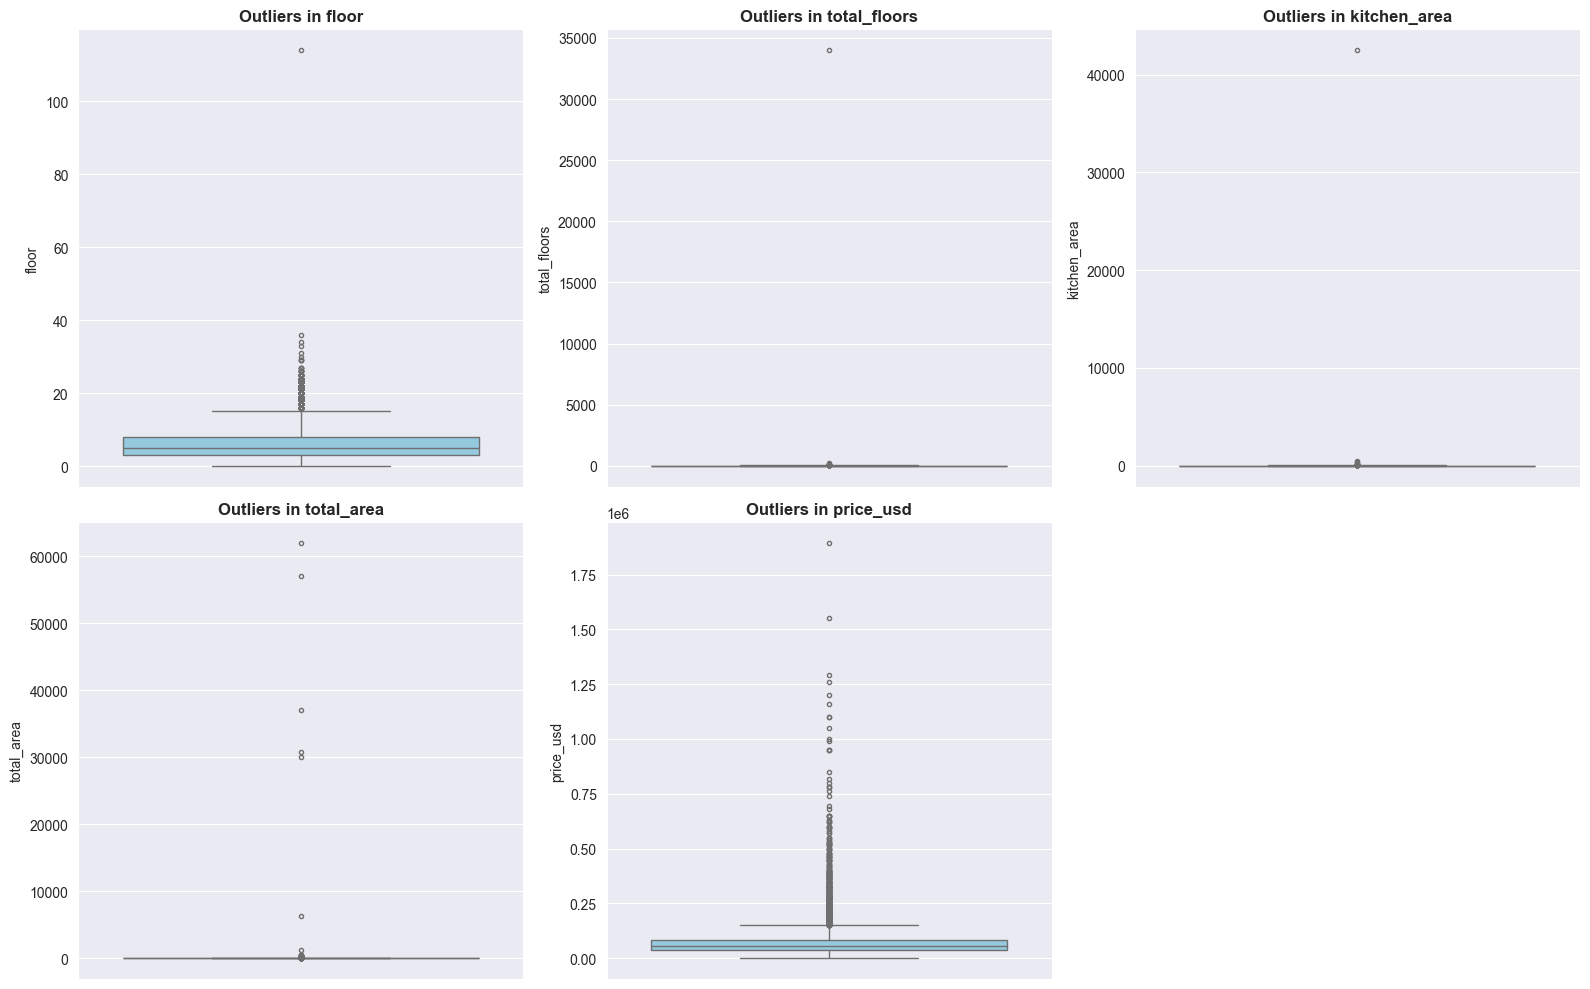

In [19]:
cols_to_plot = [
    "floor",
    "total_floors",
    "kitchen_area",
    "total_area",
    "price_usd",
]
visualize_outliers(cols_to_plot)

In [23]:
c = ["number_of_rooms", "total_area", "kitchen_area", "floor", "total_floors", "property_type_appartments_sale", "region_name", "city_name", "house_type", "year_of_commissioning"]
df = df.loc[df["floor"] < 50]
df = df.loc[df["total_floors"] < 50]
df = df.loc[df["kitchen_area"] < 60]
df = df.loc[df["total_area"] < 260]
df = df.loc[df["price_usd"] < 750000]
df.loc[df["total_floors"] > 40, "total_floors"] = 10
df.loc[df["total_floors"] > 40, "floor"] = 10
df = df.loc[df["total_floors"] >= df["floor"]]

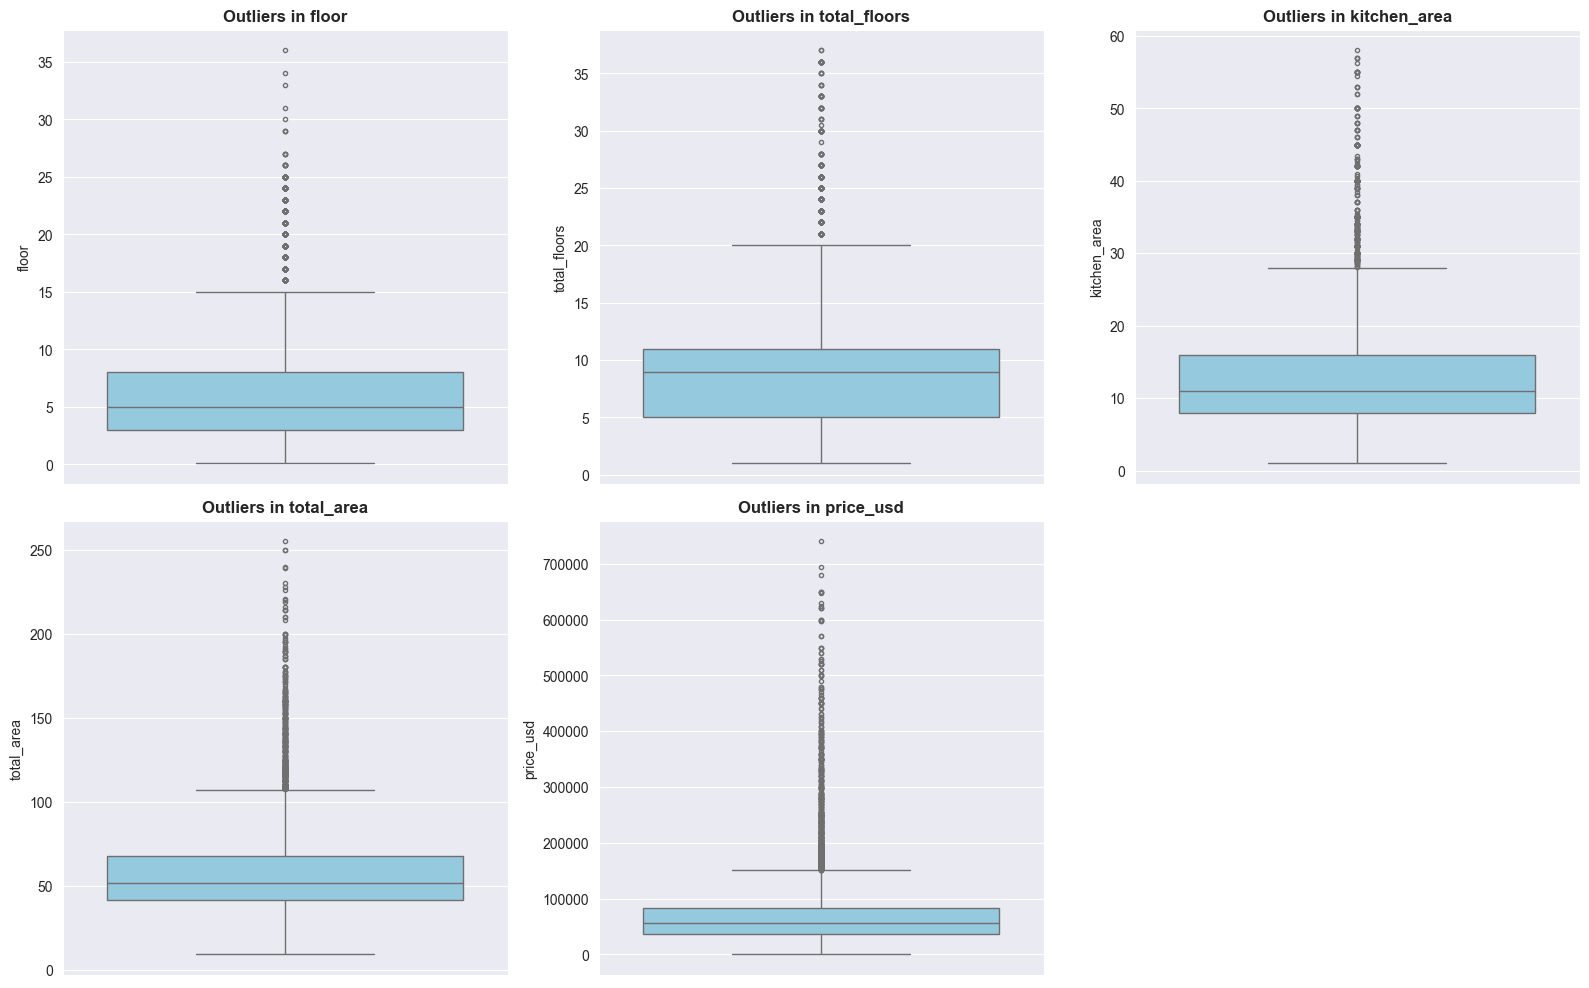

In [24]:
visualize_outliers(cols_to_plot)

In [25]:
fig = px.histogram(df, x="region_name", y="price_usd", color="apartments_object_type", barmode="group")
fig.show()

In [26]:
fig = px.histogram(df, x="region_name", y="price_usd", color="floor", barmode="group")
fig.show()

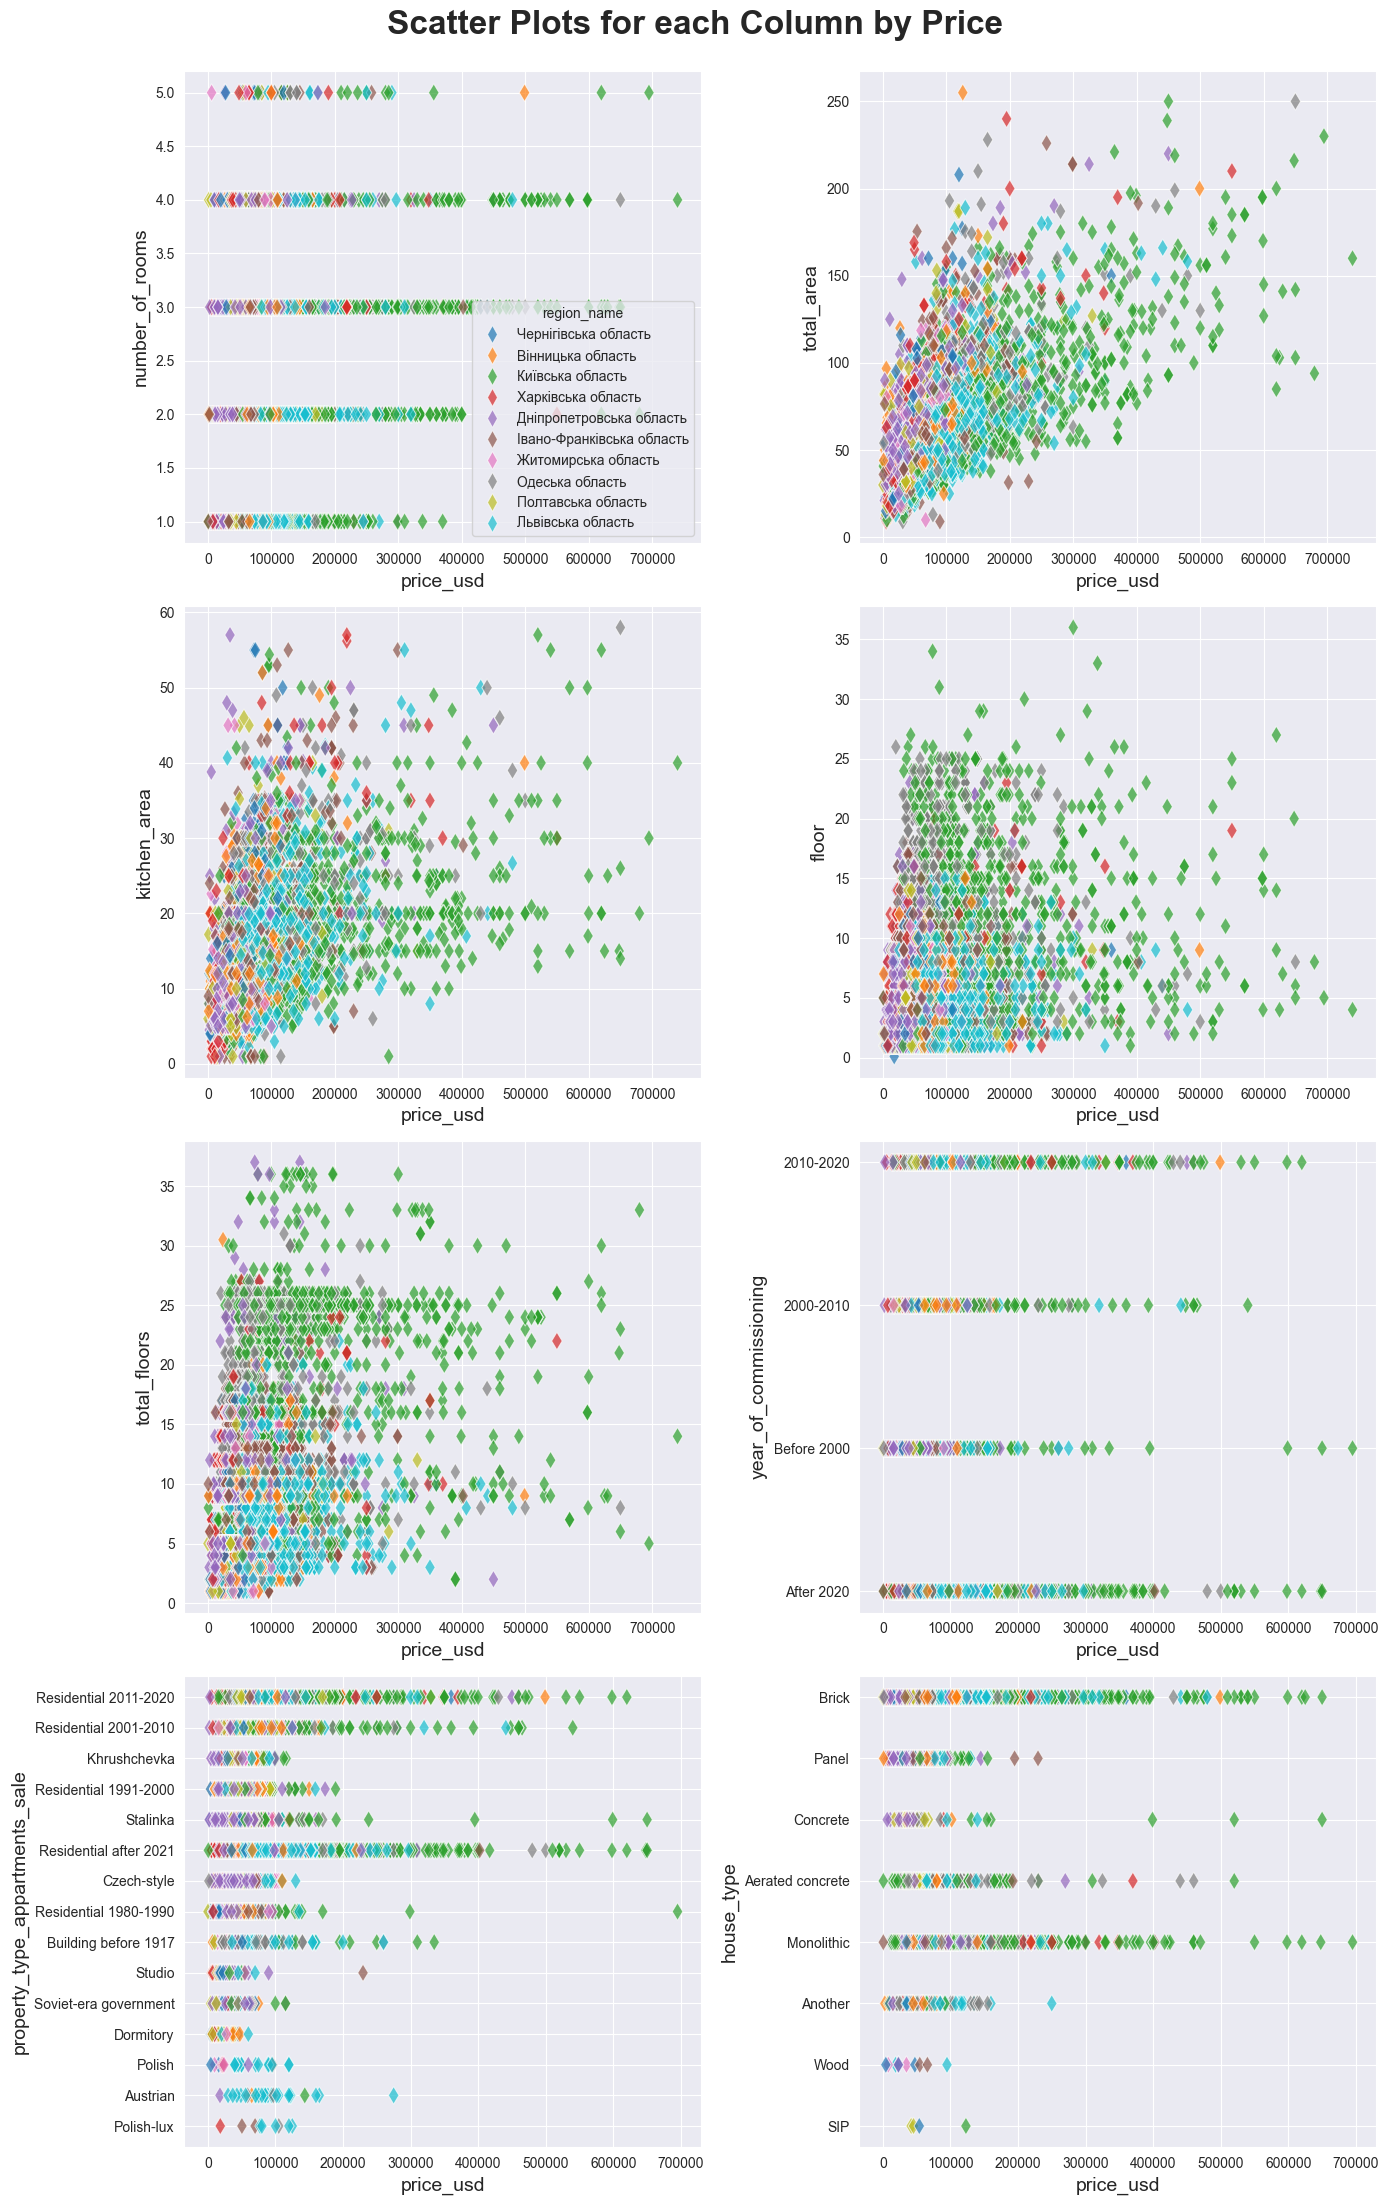

In [27]:
target_col = 'price_usd'

size=11
cols = ["number_of_rooms", "total_area", "kitchen_area", "floor", "total_floors", "year_of_commissioning", "property_type_appartments_sale", "house_type"]
n_cols = 2
n_rows = 4

fig, axes = plt.subplots(n_rows, n_cols, figsize=(size+3, size/n_cols*n_rows))
fig.suptitle(f'Scatter Plots for each Column by Price', fontsize=24, fontweight='bold', y=1)

axes_flat = axes.flatten()
legend = True
for i, col in enumerate(cols):
    ax = axes_flat[i]

    sns.scatterplot(df, y=df[col], x=df[target_col], s=80, alpha=0.7, hue="region_name", ax=ax, marker='d', legend=legend)

    ax.set_ylabel(f'{col}', fontsize=14)
    ax.set_xlabel(f'{target_col}', fontsize=14)
    legend = False

plt.tight_layout()
plt.show()

<Figure size 800x800 with 0 Axes>

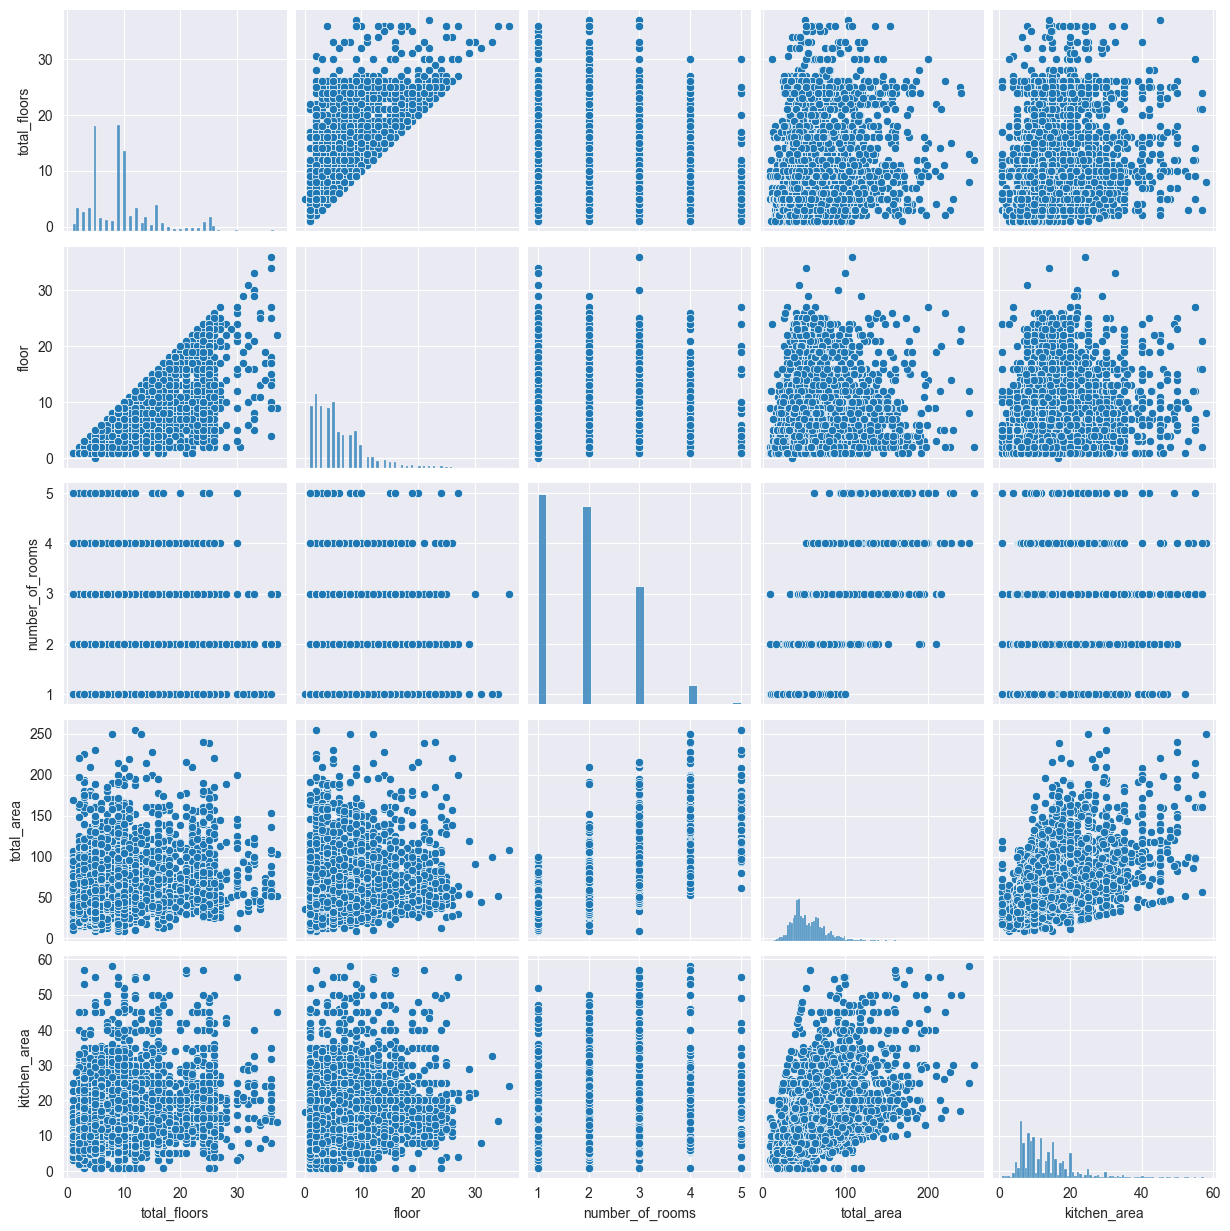

In [28]:
plt.figure(figsize=(8, 8))
sns.pairplot(df[["total_floors", "floor", "number_of_rooms", "total_area", "kitchen_area"]], diag_kind='hist')
plt.show()

In [29]:
new_cols = ["total_photos", "in_centre",  "not_kitchen_area", "floor_height", "time_on_market", "primary_market", "words_in_title", "words_in_description", "last_floor", "first_floor"]

counts = df_photos["id"].value_counts()
df["total_photos"] = df.join(counts, how='left', on="id")["count"]

centres = ["ivano-frankovsk", "kiev", "odessa", "kharkov", "chernigov", "vinnitsa", "poltava", "lvov", "dnepr", "zhitomir"]
df["in_centre"] = df["city_normalized_name"].isin(centres)

df["not_kitchen_area"] = df["total_area"] - df["kitchen_area"]

df["floor_height"] = df["floor"] / df["total_floors"]

today = pd.Timestamp.today(tz="UTC").normalize()
df["created_time_datetime"] = pd.to_datetime(df["created_time"], utc=True)
df["time_on_market"] = (today - df["created_time_datetime"]).dt.days

df["primary_market"] = df["apartments_object_type"] == "primary_market"

df["words_in_title"] = df["title"].apply(lambda x: len(re.findall(r'\w+', x)))
df["words_in_description"] = df["description"].apply(lambda x: len(re.findall(r'\w+', x)))

df["last_floor"] = df["floor"] == df["total_floors"]
df["first_floor"] = df["floor"] <= 1

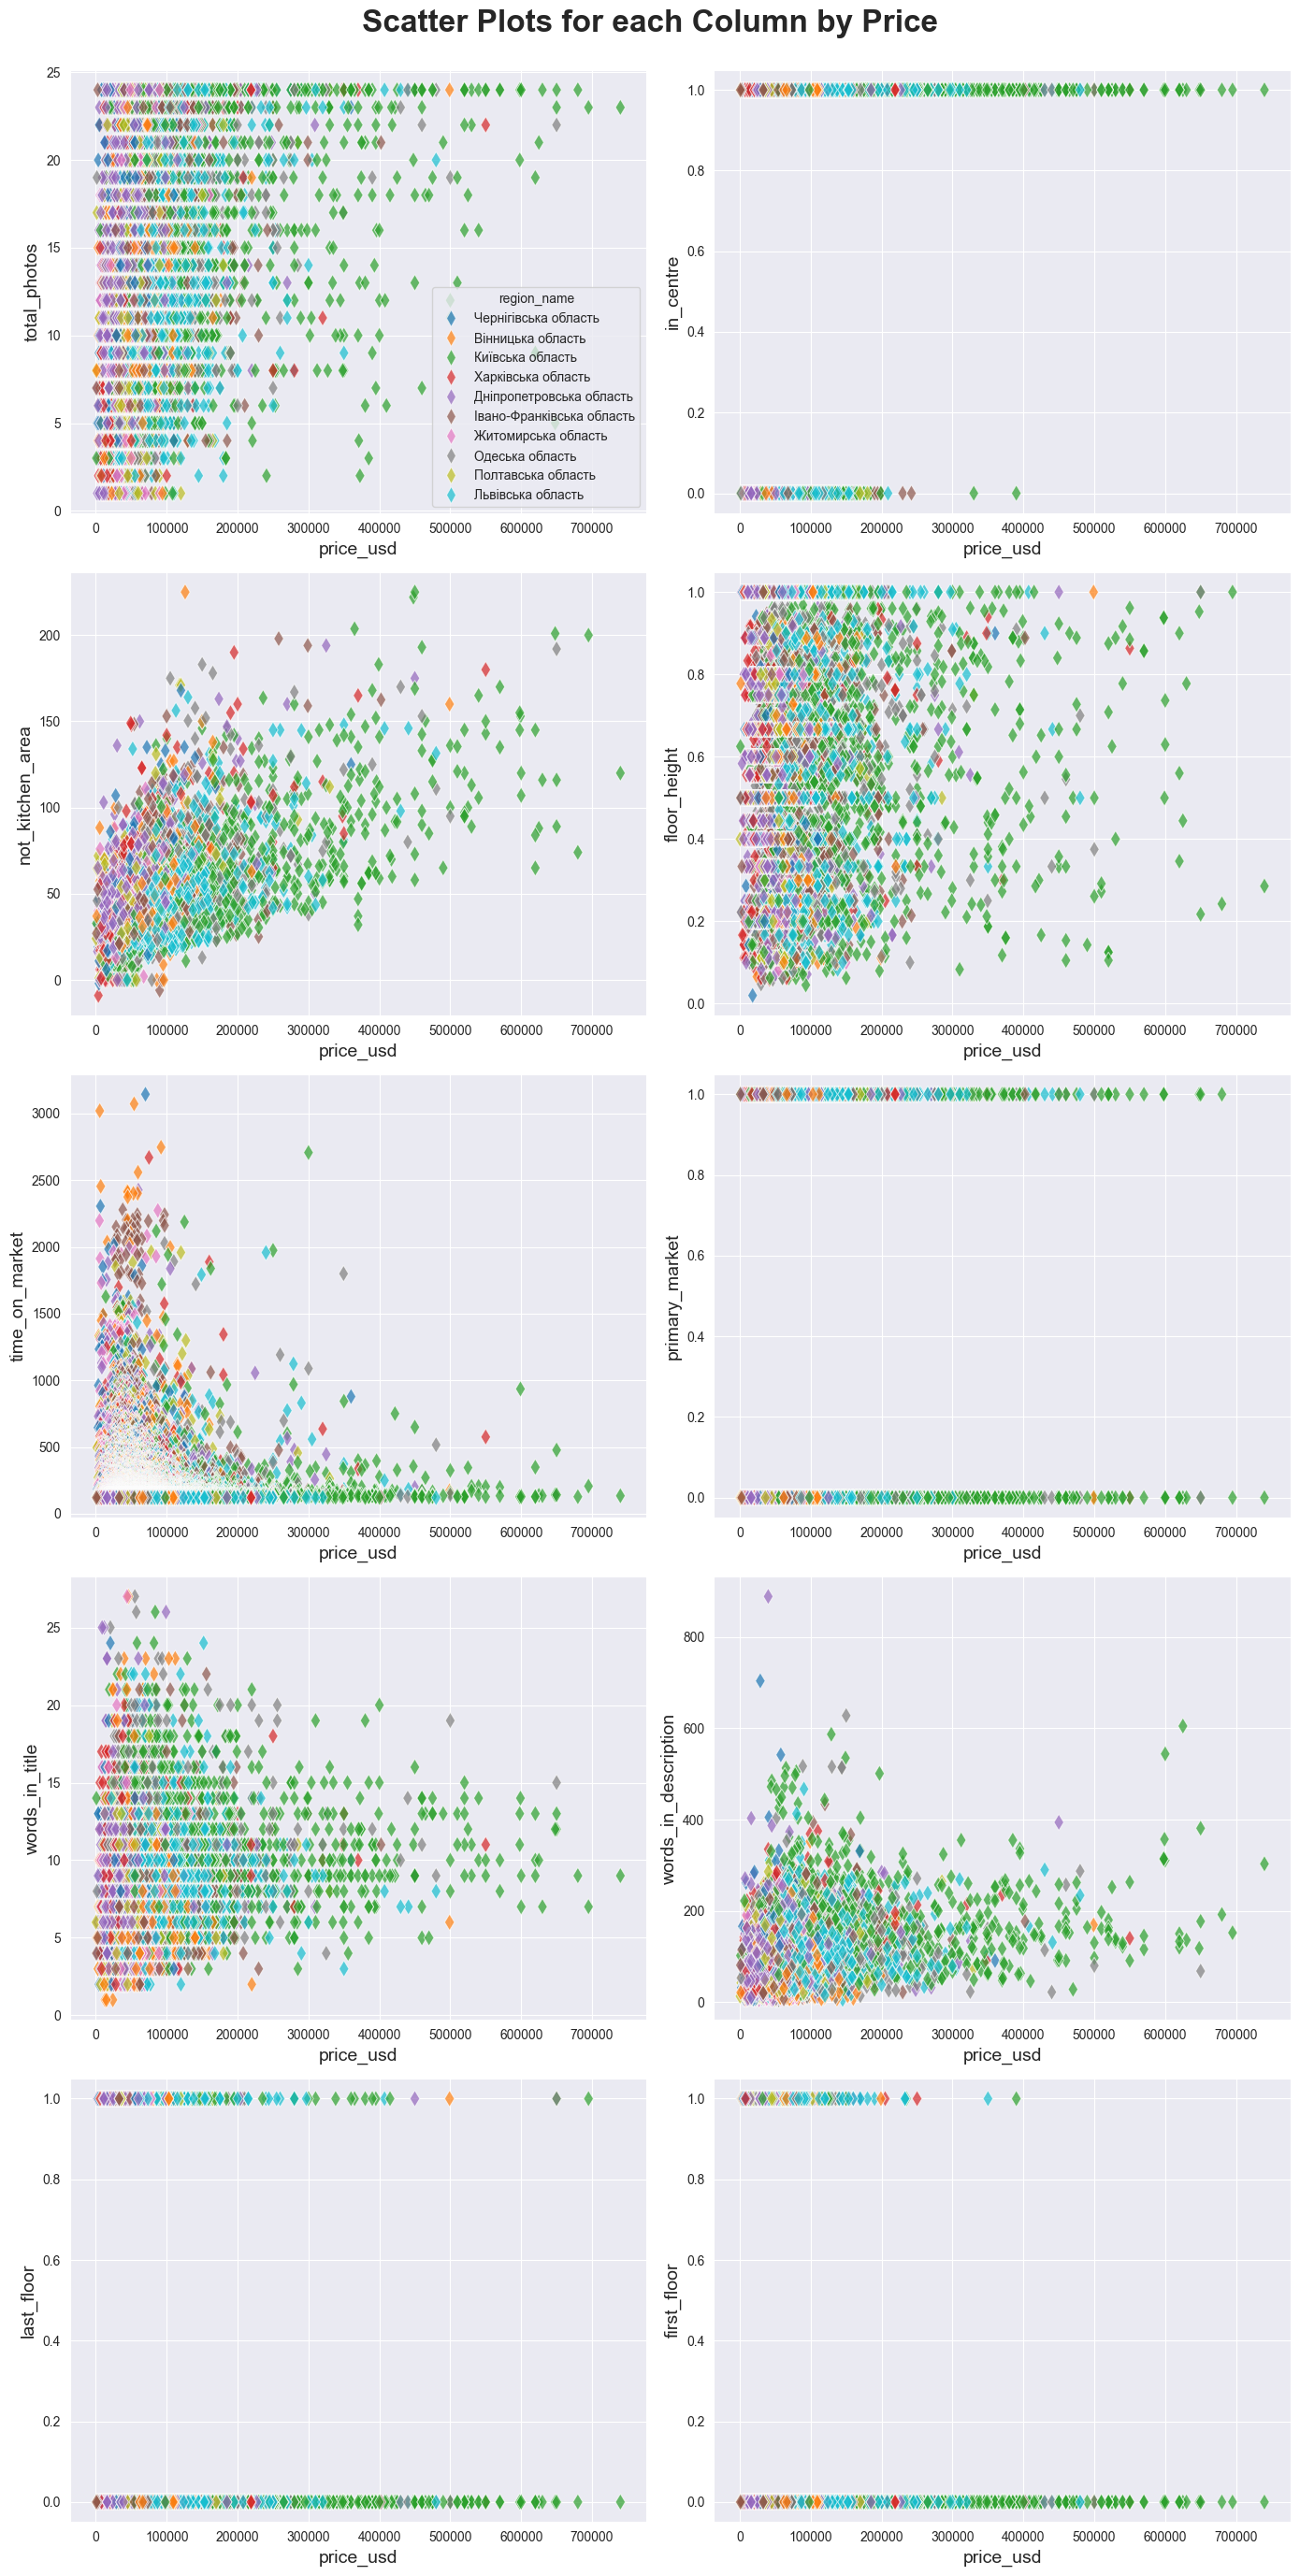

In [30]:
target_col = 'price_usd'

size=11
n_cols = 2
n_rows = 5

fig, axes = plt.subplots(n_rows, n_cols, figsize=(size+3, size/n_cols*n_rows))
fig.suptitle(f'Scatter Plots for each Column by Price', fontsize=24, fontweight='bold', y=1)

axes_flat = axes.flatten()
legend = True
for i, col in enumerate(new_cols):
    ax = axes_flat[i]

    sns.scatterplot(df, y=df[col], x=df[target_col], s=80, alpha=0.7, hue="region_name", ax=ax, marker='d', legend=legend)

    ax.set_ylabel(f'{col}', fontsize=14)
    ax.set_xlabel(f'{target_col}', fontsize=14)
    legend = False

plt.tight_layout()
plt.show()

In [13]:
df.info()

<class 'pandas.DataFrame'>
Index: 11981 entries, 0 to 12052
Data columns (total 58 columns):
 #   Column                             Non-Null Count  Dtype              
---  ------                             --------------  -----              
 0   id                                 11981 non-null  int64              
 1   title                              11981 non-null  str                
 2   url                                11981 non-null  str                
 3   description                        11981 non-null  str                
 4   price_uah                          11981 non-null  float64            
 5   city_id                            11981 non-null  int64              
 6   city_name                          11981 non-null  str                
 7   city_normalized_name               11981 non-null  str                
 8   region_id                          11981 non-null  int64              
 9   region_name                        11981 non-null  str            

### Preparing dataset for training

In [14]:
df = df.drop(columns=["id", "title", "url", "description", "price_uah", "city_id", "city_name", "region_id", "region_name", "district_id", "district_name", "created_time", "last_refresh_time", "apartments_object_type", "zkh", "appliances", "multimedia_2", "comfort", "communications", "ecosystem_1_km", "cooperate", "infrastructure_500_m", "is_exchange", "eoselia", "property_type_appartments_sale_id", "house_type_id", "bathroom_id", "repair_id", "multimedia", "created_time_datetime"])

In [15]:
df.loc[df["apartments_dev_type"].isna(), "apartments_dev_type"] = "unknown"
df.loc[df["property_type_appartments_sale"].isna(), "property_type_appartments_sale"] = "unknown"
df.loc[df["house_type"].isna(), "house_type"] = "unknown"
df.loc[df["year_of_commissioning"].isna(), "year_of_commissioning"] = "unknown"
df.loc[df["bathroom"].isna(), "bathroom"] = "unknown"
df.loc[df["heating"].isna(), "heating"] = "unknown"
df.loc[df["repair"].isna(), "repair"] = "unknown"
df.loc[df["furnish"].isna(), "furnish"] = "unknown"
df.loc[df["layout"].isna(), "layout"] = "unknown"

df["in_centre"] = df["in_centre"].astype(float)
df["primary_market"] = df["primary_market"].astype(float)
df["last_floor"] = df["last_floor"].astype(float)
df["first_floor"] = df["first_floor"].astype(float)

In [16]:
df.info()

<class 'pandas.DataFrame'>
Index: 11981 entries, 0 to 12052
Data columns (total 28 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   city_normalized_name            11981 non-null  str    
 1   region_normalized_name          11981 non-null  str    
 2   commission                      11981 non-null  float64
 3   property_type_appartments_sale  11981 non-null  str    
 4   floor                           11981 non-null  float64
 5   total_floors                    11981 non-null  float64
 6   total_area                      11981 non-null  float64
 7   kitchen_area                    11981 non-null  float64
 8   house_type                      11981 non-null  str    
 9   apartments_dev_type             11981 non-null  str    
 10  bathroom                        11981 non-null  str    
 11  heating                         11981 non-null  str    
 12  repair                          11981 non-null  

In [17]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split

In [18]:
df_ml = df.copy()

In [19]:
onehot_encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False, drop="first").set_output(transform="pandas")
onehot_encoded = onehot_encoder.fit_transform(df_ml[["region_normalized_name", "house_type", "apartments_dev_type", "bathroom", "heating", "repair", "furnish", "year_of_commissioning", "layout", "property_type_appartments_sale"]])
df_ml = pd.concat([df_ml, onehot_encoded], axis=1).drop(columns=["region_normalized_name", "house_type", "apartments_dev_type", "bathroom", "heating", "repair", "furnish", "year_of_commissioning", "layout", "property_type_appartments_sale"])

In [20]:
df_ml.shape

(11981, 88)

In [21]:
target = 'price_usd'
X = df_ml.drop(columns=[target, "city_normalized_name"])

corr_matrix = X.corr().abs()

upper_triangle = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

threshold = 0.9
to_drop = [column for column in upper_triangle.columns if any(upper_triangle[column] > threshold)]

print(f"Cols to drop: {to_drop}")

df_ml = df_ml.drop(columns=to_drop)

Cols to drop: ['not_kitchen_area', 'property_type_appartments_sale_Residential 2011-2020', 'property_type_appartments_sale_Residential after 2021', 'property_type_appartments_sale_unknown']


In [22]:
X = df_ml.drop(target, axis=1)
y = df_ml[target]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [23]:
city_counts = X_train["city_normalized_name"].value_counts()
big_cities = city_counts[city_counts >= 40].index.tolist()

def encode_cities(df, column):
    cities_encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False, drop="first").set_output(transform="pandas")
    df.loc[~df[column].isin(big_cities), column] = "other"
    cities = cities_encoder.fit_transform(df[[column]])
    return pd.concat([df, cities], axis=1).drop(columns=[column])

In [24]:
X_train = encode_cities(X_train, "city_normalized_name")
X_train.shape

(9584, 102)

In [25]:
minmax_scaler = MinMaxScaler(clip=True)
standard_scaler = StandardScaler()

minmax_cols = ["total_photos", "number_of_rooms"]
standard_cols = ["floor", "total_floors", "total_area", "kitchen_area", "time_on_market", "words_in_title", "words_in_description"]

minmax_scaler.fit(X_train[minmax_cols])
X_train[minmax_cols] = minmax_scaler.transform(X_train[minmax_cols])

standard_scaler.fit(X_train[standard_cols])
X_train[standard_cols] = standard_scaler.transform(X_train[standard_cols])
X_train.head(10)

,commission,floor,total_floors,total_area,kitchen_area,number_of_rooms,total_photos,in_centre,floor_height,time_on_market,...,city_normalized_name_krivoyrog,city_normalized_name_lvov,city_normalized_name_odessa,city_normalized_name_other,city_normalized_name_poltava,city_normalized_name_sofievskaya-borschagovka,city_normalized_name_sokolniki_38727,city_normalized_name_vinniki_37885,city_normalized_name_vinnitsa,city_normalized_name_zhitomir
6701,1.0,0.699172,1.072789,0.462372,1.877203,0.25,0.913043,1.0,0.562500,-0.393718,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
389,1.0,0.028587,1.072789,-1.266667,-1.402192,0.00,0.478261,1.0,0.375000,2.551519,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
839,0.0,-0.194941,-0.626033,3.356162,0.166214,0.75,0.260870,1.0,0.833333,1.249694,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3763,0.0,-0.641998,-0.965798,-0.478109,-1.202576,0.25,0.521739,0.0,0.750000,-0.188766,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
5465,1.0,0.028587,1.582436,-1.024714,-0.118950,0.00,0.391304,1.0,0.315789,-0.329196,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
281,1.0,-0.865526,-0.795915,0.285530,0.879126,0.25,0.782609,1.0,0.400000,3.143603,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8176,0.0,0.699172,-0.116386,-0.662990,-0.404115,0.00,0.391304,1.0,1.000000,-0.420286,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4462,1.0,-0.194941,-0.116386,-1.024714,-1.117027,0.00,0.347826,1.0,0.555556,-0.264674,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3142,1.0,0.699172,1.072789,1.555582,-0.404115,0.75,0.478261,1.0,0.562500,-0.101471,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8707,0.0,2.263870,3.451141,-0.180692,-0.118950,0.00,0.695652,1.0,0.533333,-0.424081,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [26]:
X_test = encode_cities(X_test, "city_normalized_name")
X_test[minmax_cols] = minmax_scaler.transform(X_test[minmax_cols])
X_test[standard_cols] = standard_scaler.transform(X_test[standard_cols])

In [27]:
X_train.to_csv("ML_ready_datasets/X_train.csv", index=True)
y_train.to_csv("ML_ready_datasets/y_train.csv", index=True)
X_test.to_csv("ML_ready_datasets/X_test.csv", index=True)
y_test.to_csv("ML_ready_datasets/y_test.csv", index=True)